# Fase 3 — Busca
Embeddings multilíngues (`intfloat/multilingual-e5-base`) + índice vetorial (FAISS).

- recall@1 e recall@3 nas respondíveis (meta: recall@3 ≥ 0,8)
- curva acerto × recusa para escolher o limiar (escolhido no split **dev**)

In [1]:
import sys, os
from pathlib import Path
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(RAIZ)
sys.path.insert(0, str(RAIZ / "src"))
sys.path.insert(0, str(RAIZ / "scripts"))
print(RAIZ)

.


In [2]:
%run scripts/03_indexar.py

W1108 15:30:36.320000 3312 .venv\Lib\site-packages\torch\utils\flop_counter.py:113] triton not found; flop counting will not work for triton kernels


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Batches:   0%|          | 0/6 [00:00<?, ?it/s]

82 trechos indexados com intfloat/multilingual-e5-base em 12s -> .\base\indice
Próximo: python scripts/04_avaliar_busca.py


In [3]:
%run scripts/04_avaliar_busca.py

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]


=== Recall da busca (respondíveis) ===


dev    n=10  recall@1=0.400  recall@3=0.600
todas  n=40  recall@1=0.475  recall@3=0.775
ATENÇÃO: recall@3 < 0,8. Revise o fatiamento antes de seguir (ver PASSO_A_PASSO.md, passo 4).
  errou r01: esperado ctb-art181, veio ['sp-cartilha-calcadas-s04-p1', 'sp-cartilha-calcadas-s01-p1', 'sp-dec59671-art10-p1']  — o carro tá em cima da calçada, pode isso?
  errou r06: esperado sp-lei15442-anexo|sp-lei15442-art15, veio ['sp-subpref-calcadas-s01-p4', 'sp-subpref-calcadas-s01-p2', 'sp-dec59671-art1-p1']  — se o dono não arrumar a calçada ele leva multa? de quanto?
  errou r07: esperado sp-lei15442-art11, veio ['sp-dec59671-art32-p1', 'sp-subpref-calcadas-s01-p4', 'sp-lei15442-art14-p1']  — Qual é o prazo para regularizar a calçada depois da intimação?
  errou r09: esperado sp-dec59671-art4|sp-lei15442-art8, veio ['sp-cartilha-calcadas-s05-p1', 'sp-cartilha-calcadas-s02-p1', 'sp-dec59671-art24-p1']  — quanto de espaço livre tem que ter na calçada pra gente passar?
  errou r12: esperado sp-dec59

{'limiar': 0.17, 'acerto_respondiveis': 0.6, 'recusa_correta_nao_consta': 1.0, 'equilibrio': 0.8}
faixa de scores observada: 0.000 a 1.000


gráfico: .\avaliacao\curva_limiar.png

limiar salvo em .\avaliacao\limiar.json. Próximo: python scripts/05_testar_geracao.py


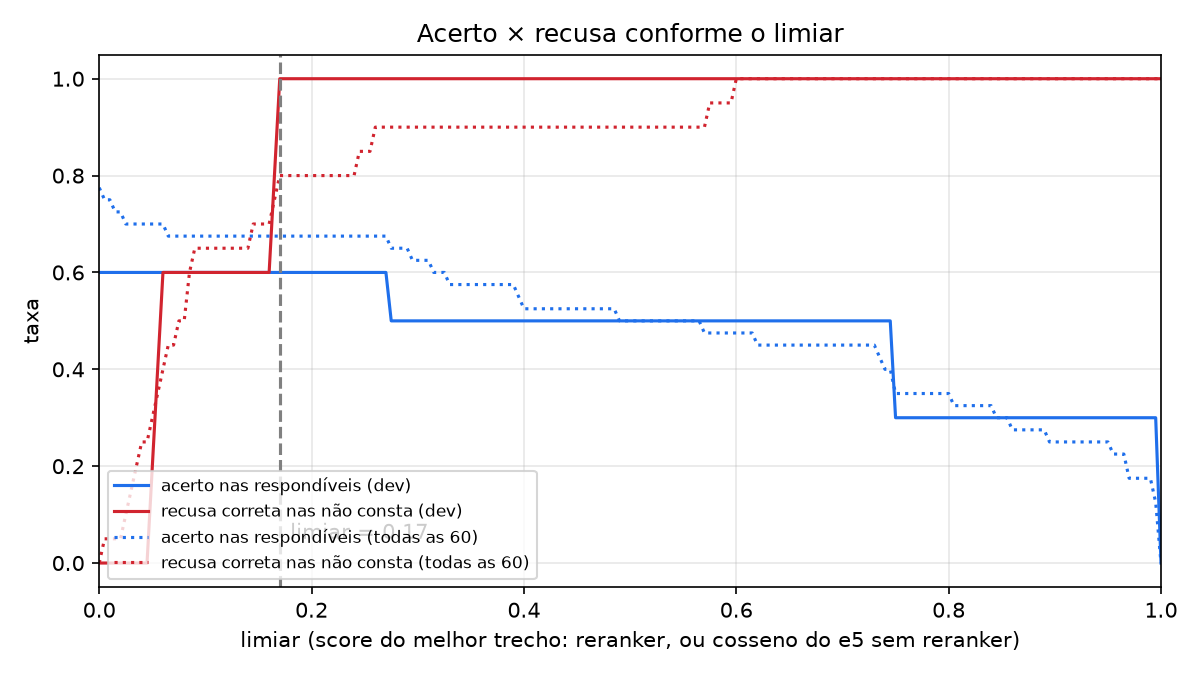

In [4]:
from IPython.display import Image
Image('avaliacao/resultados/curva_limiar.png')

In [5]:
import json, pandas as pd
b = json.load(open('avaliacao/busca.json', encoding='utf-8'))
display(pd.DataFrame(b['recall']).T)
pd.DataFrame(b['curva_dev']).set_index('limiar').iloc[::4]

,n,recall@1,recall@3
dev,10.0,0.400,0.600
todas,40.0,0.475,0.775


,acerto_respondiveis,recusa_correta_nao_consta,equilibrio
limiar,,,
0.00,0.6,0.0,0.30
0.02,0.6,0.0,0.30
0.04,0.6,0.0,0.30
0.06,0.6,0.6,0.60
0.08,0.6,0.6,0.60
0.10,0.6,0.6,0.60
0.12,0.6,0.6,0.60
0.14,0.6,0.6,0.60
0.16,0.6,0.6,0.60


**Justificativa do limiar** (escreva 2–3 frases): por que este valor equilibra acerto nas respondíveis e recusa nas "não consta", e o que se perde subindo ou descendo.